In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

# Convertir las columnas de fechas de orders

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)


## Línea: pedidos por mes `plt.plot`
*    Cargar orders y convertir order_purchase_timestamp a datetime.
*    Filtrar order_status == 'delivered' (opcional).
*    Crear columna de mes con .dt.to_period('M').
*    groupby por mes y contar order_id con nunique.
*    Recortar meses extremos (2016 y sept–oct 2018 casi no tienen datos): buena lección de "mira tus datos antes de graficar".
*    Graficar mes vs. número de pedidos; título, etiquetas y rotar ticks.

In [12]:
# sólo ventas entregadas
df1= orders[orders["order_status"]=="delivered"]
# para evitar saturar la memoria y la vista, corto sólo las columnas que necesito
df1=df1[["order_purchase_timestamp","order_id"]]
# Crear una columna mes a partir de "order_purchase_timestamp"
df1["month"]= df1["order_purchase_timestamp"].dt.to_period("M")
# utilizo sample(5) para mostrar 5 elemntos aleatorios del dataframe
display(df1.sample(5))
#agrupar por mes y contar order_id
resultado = df1.groupby("month")["order_id"].nunique()
display(resultado)

,order_purchase_timestamp,order_id,month
26578,2017-05-12 09:24:26,4c05a3711a90dee7f6336af0f3385142,2017-05
57224,2018-06-12 10:36:52,a2ef683013be03a1d7903ecc7d17d48d,2018-06
92913,2017-10-11 14:51:57,dad4892a17667aadb726ace75b1a16b8,2017-10
54515,2017-10-10 10:24:59,5a872b37ac143343156a0dc43f1a19fc,2017-10
61945,2017-11-16 19:22:04,2c529e48633e1c206e07f886dc2ad423,2017-11


month
2016-09       1
2016-10     265
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, Name: order_id, dtype: int64

<Axes: title={'center': 'Pedidos por mes'}, xlabel='Mes', ylabel='Cantidad de ventas'>

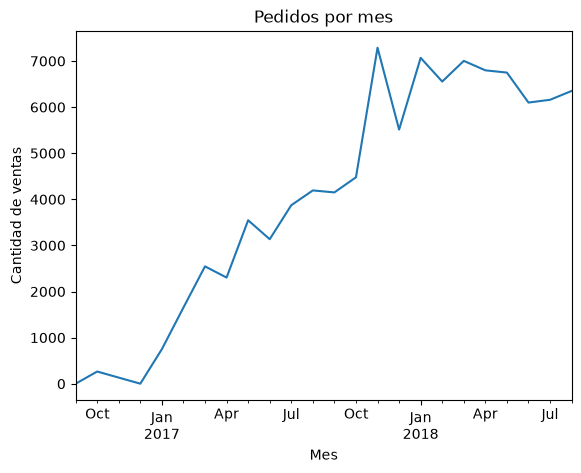

In [13]:
resultado.plot(
    kind= "line",
    title= "Pedidos por mes",
    xlabel= "Mes",
    ylabel="Cantidad de ventas"
)

## Barras horizontales: top 10 categorías por ingreso `plt.barh`
*    Merge order_items + products por product_id.
*    Merge con product_category_name_translation por product_category_name (nombres en inglés).
*    groupby categoría → suma de price.
*    Tomar las 10 mayores con .nlargest(10).
*    Invertir el orden para que la mayor quede arriba y graficar con barh.

<Axes: title={'center': 'Top 10 categorías por ingreso'}, xlabel='categorías', ylabel='Ingreso'>

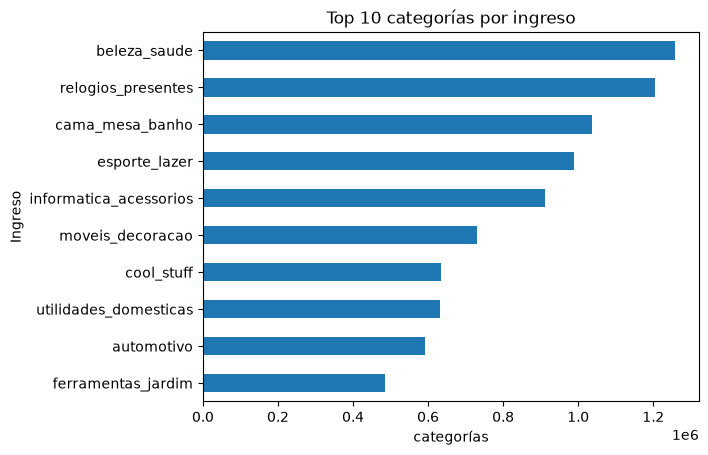

In [14]:
df2_order_items = order_items[["price", "product_id"]]
df2_products = products[["product_id", "product_category_name"]]
df2 = df2_products.merge(df2_order_items, on = "product_id", how = "left")
resultado = df2.groupby("product_category_name")["price"].sum().nlargest(10).sort_values(ascending = True)
resultado.plot(
    kind = "barh",
    title = "Top 10 categorías por ingreso",
    xlabel = "categorías",
    ylabel = "Ingreso"
)


## Histograma: distribución del precio `plt.hist`
*    Usar order_items['price'].
*    Primer histograma directo: se verá muy sesgado.
*    Repetir con bins en escala log o con np.log10(price).
*    Discusión: por qué la media engaña. Marcar media y mediana con axvlin

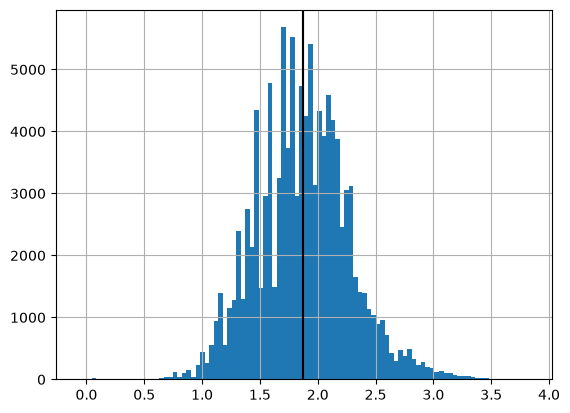

In [15]:
import numpy as np
df3= order_items[["price"]]
df3["log"]=df3["price"].apply(np.log10)
df3["log"].hist(bins=100)
mean = df3["log"].mean()
median = df3["log"].median()
plt.axvline(mean, color = "red")
plt.axvline(median,color="black" )
#La media y mediana son iguales

<Axes: ylabel='Frequency'>

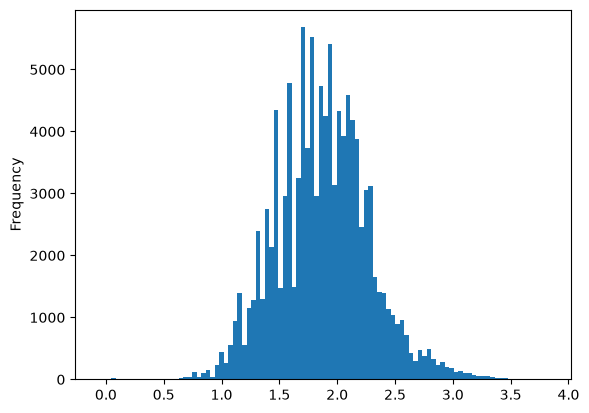

In [16]:
df3["log"].plot(kind="hist",bins=100)

## Histograma comparativo: días de entrega reales vs. estimados `hist + alpha`
*   En orders, convertir a datetime las columnas de compra, entrega real y entrega estimada.
*   Calcular dias_reales = entregado − compra y dias_estimados = estimado − compra (en .dt.days).
*   Eliminar NaN (pedidos no entregados).
*   Dos histogramas en el mismo eje con alpha=0.5 y leyenda.

<Axes: ylabel='Frequency'>

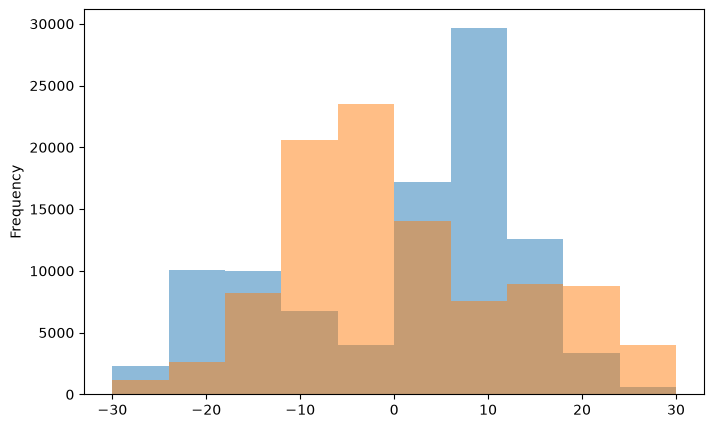

In [17]:
import matplotlib.pyplot as plt
lienzo, pintura= plt.subplots(figsize=(8,5))
df4 = orders[["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]]
df4["dias_reales"] = df4["order_delivered_customer_date"].dt.day - df4["order_purchase_timestamp"].dt.day
df4["dias_estimados"] = df4["order_estimated_delivery_date"].dt.day - df4["order_purchase_timestamp"].dt.day
df4.dropna(subset=["order_delivered_customer_date"])
df4.isna().sum()
df4["dias_reales"].plot(
    kind="hist",
    alpha=0.5
)
df4["dias_estimados"].plot(
    kind="hist",
    alpha=0.5
)

## Boxplot: calificación vs. días de retraso `plt.boxplot`
* En ``orders``, calcular retraso = entregado − estimado en días.
* Merge con ``order_reviews`` por ``order_id`` (quitar duplicados por ``order_id``: hay pedidos con más de una reseña).
* Agrupar el retraso por ``review_score`` (1–5) → lista de 5 arrays.
* Pasar la lista a ``boxplot`` con etiquetas 1–5.
* Conclusión esperada: las calificaciones de 1 tienen retrasos mucho mayores.

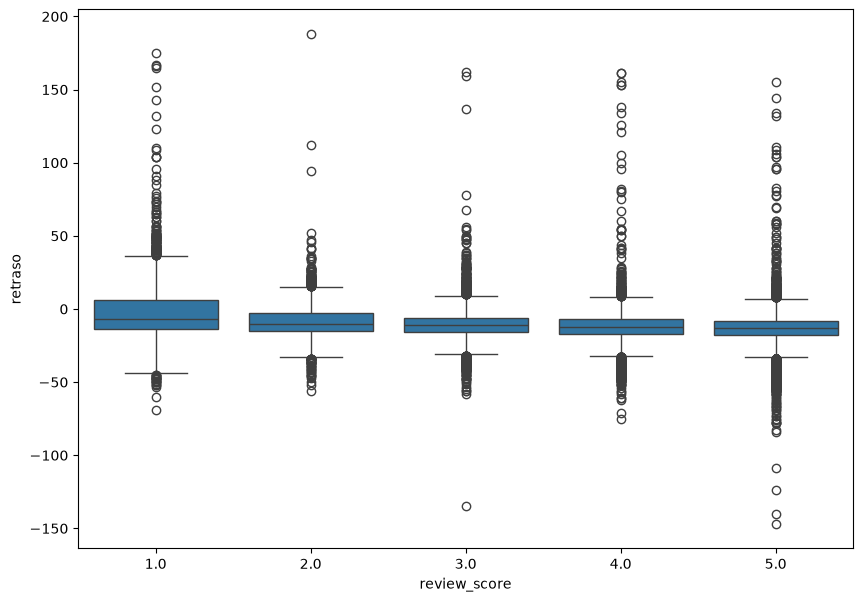

In [18]:
df_5 = orders[["order_id", "order_delivered_customer_date", "order_estimated_delivery_date"]]
df_5["retraso"] = (df_5["order_delivered_customer_date"] - df_5["order_estimated_delivery_date"]).dt.days
orders_df_5 = df_5[["order_id", "retraso"]]
reviews_df_5 = order_reviews[["order_id", "review_score"]].drop_duplicates(subset="order_id")
merge5 = orders_df_5.merge(reviews_df_5, on = "order_id", how = "left")
merge5 = merge5.dropna()
lienzo, pintura = plt.subplots(figsize = (10,7))
sns.boxplot(data = merge5, x = "review_score", y = "retraso")
plt.show()

## Barras con error: calificación promedio a tiempo vs. tarde
 ``plt.bar(yerr=)``
* Usar el mismo merge de la gráfica 5.
* Crear columna booleana ``tarde = retraso > 0``.
* ``groupby('tarde')`` → ``mean`` y ``std`` de ``review_score``.
* Graficar barras con ``yerr=std``.

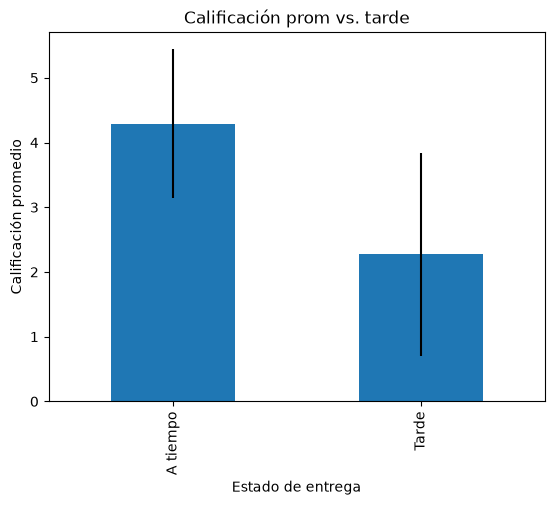

In [19]:
df_6=merge5
df_6["tarde"] = df_6["retraso"] > 0
df_6["clasificacion"] = df_6["tarde"].apply(
    lambda x: "A tiempo" if x == False else "Tarde"
)
df_6 = merge5.groupby("clasificacion")["review_score"].agg(["mean", "std"])
lienzo, pintura = plt.subplots()
df_6["mean"].plot(
    kind = "bar",
    yerr = df_6["std"],
    title = "Calificación prom vs. tarde",
    xlabel = "Estado de entrega",
    ylabel = "Calificación promedio"
)
plt.show()

## Pastel / dona: métodos de pago
`plt.pie`
* ``order_payments`` → ``value_counts()`` de ``payment_type``.
* Agrupar ``not_defined`` y categorías pequeñas en ``"otros"``.
* Graficar con ``autopct='%1.1f%%';`` para dona, ``wedgeprops={'width':0.4}``.
* Discusión: por qué los pasteles suelen ser mala idea; comparar con la versión en barras.

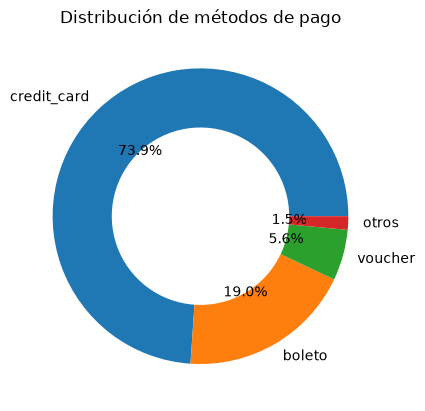

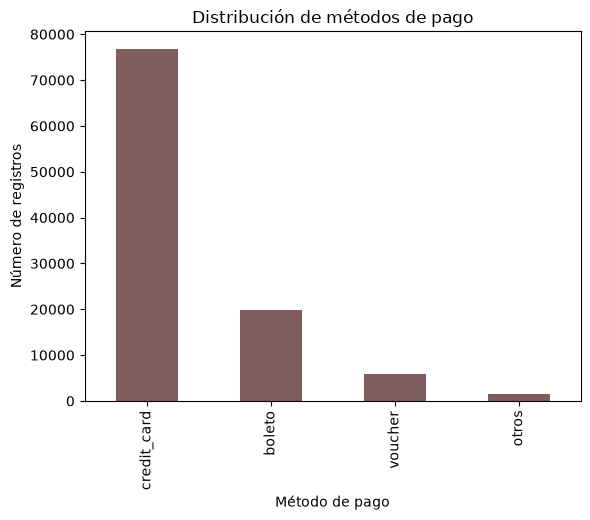

In [20]:
fig, ax = plt.subplots()
df_7 = payments
df_7["payment_type"].value_counts()
def hola(x):
    if x in ["not_defined", "debit_card"]:
        return "otros"
    else:
        return x
df_7["payment_type"] = df_7["payment_type"].apply(hola)
df_7["payment_type"].value_counts().plot(
    kind= "pie",
    autopct= "%1.1f%%",
    wedgeprops={'width':0.4},
    title = "Distribución de métodos de pago"
)
fig, ax = plt.subplots()
df_7["payment_type"].value_counts().plot(
    kind = "bar",
    title = "Distribución de métodos de pago",
    color="#805d5d",
    xlabel = "Método de pago",
    ylabel = "Número de registros"
)
plt.show()

## Barras agrupadas: monto promedio por mensualidades y método de pago 
`pivot + bar`
* Tomar `order_payments`.
* Crear rangos de `payment_installments` con ``pd.cut``: 1, 2–3, 4–6, 7–10, más de 10.
* `pivot_table`: index = rango, columns = `payment_type`, values = `payment_value`, aggfunc = ``'mean'``.
* Barras agrupadas desplazando cada serie con ``x + i*ancho`` (o ``df.plot(kind='bar')``).

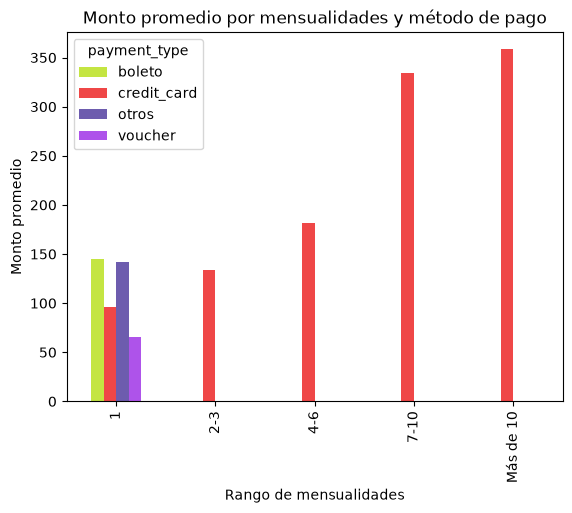

In [21]:
df_8 = payments
df_8["mensualidades"] = pd.cut(
    df_8["payment_installments"],
    bins=[0, 1, 3, 6, 10, np.inf],
    labels=["1", "2-3", "4-6", "7-10", "Más de 10"]
)

pivot = df_8.pivot_table( 
    index = "mensualidades",
    columns = "payment_type",
    values = "payment_value",
    aggfunc = "mean"
)

pivot.plot(
    kind = "bar",
    title = "Monto promedio por mensualidades y método de pago",
    color=("#c4e542","#ef4747","#6d5cae","#ae53ea"),
    xlabel = "Rango de mensualidades",
    ylabel = "Monto promedio"
)
plt.show()

## Barras apiladas: estado del pedido por estado de la república
``pivot + bottom=``
* Merge ``orders`` + ``customers`` por ``customer_id``.
* ``pivot_table``: index = ``customer_state``, columns = ``order_status``, values = ``order_id``, aggfunc = ``'count'``, ``fill_value=0``.
* Normalizar por fila (dividir entre ``.sum(axis=1)``) para tener porcentajes.
* Quedarse con los 10 estados con más pedidos.
* Apilar barras con un loop acumulando ``bottom``.

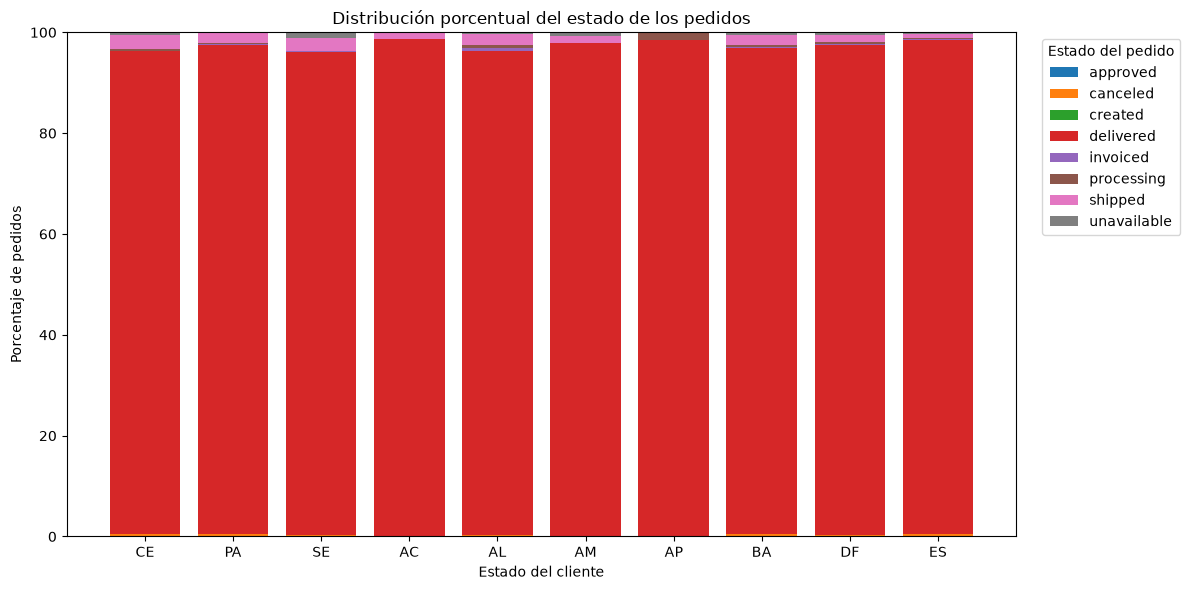

In [22]:
df_9 = orders.merge(customers, on = "customer_id", how = "left")
df_9 = df_9[["customer_state", "customer_id", "order_status", "order_id"]]
pivot_df_9 = df_9.pivot_table(
    index = "customer_state",
    columns = "order_status",
    values = "order_id",
    aggfunc= "count",
    fill_value = 0
)
def hola_maestro(fila):
    total = fila.sum()
    if total == 0:
        return fila * 0
    else:
        return (fila/total) * 100
porcentajes=pivot_df_9.apply(hola_maestro, axis = 1)
top_df_9 = porcentajes.sum(axis=1).nlargest(10).index
porcentajes=porcentajes.loc[top_df_9]
fig, ax=plt.subplots(figsize=(12, 6))
bottom=np.zeros(len(porcentajes))
for estado_pedido in porcentajes.columns:
    valores = porcentajes[estado_pedido].values
    ax.bar(
        porcentajes.index,
        valores,
        bottom=bottom,
        label=estado_pedido
    )
    bottom += valores
ax.set_title('Distribución porcentual del estado de los pedidos')
ax.set_xlabel('Estado del cliente')
ax.set_ylabel('Porcentaje de pedidos')
ax.legend(title='Estado del pedido', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

## Dispersión: peso del producto vs. costo de envío `plt.scatter`
*    Merge order_items + products por product_id.
*    Tomar product_weight_g y freight_value; quitar NaN.
*    Muestrear con .sample(3000) (110k puntos saturan la gráfica).
*    Graficar con alpha bajo; opcionalmente ejes en escala log.
*    Extra: colorear por price con c= y agregar plt.colorbar().

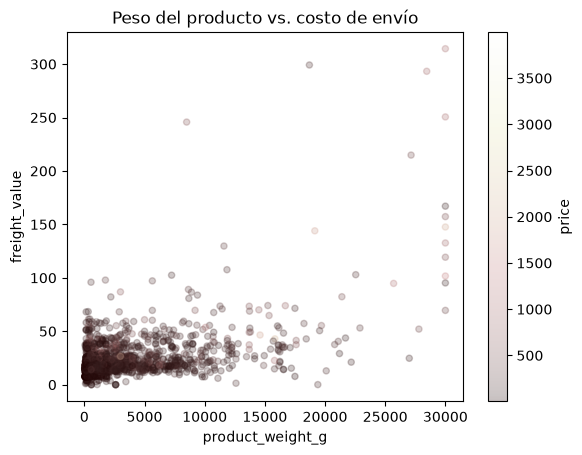

In [23]:
df_10 = order_items.merge(products, on = "product_id", how = "left")
df_10 = df_10.dropna(how= "all")
df_10 = df_10.sample(3000)
df_10[["product_weight_g", "freight_value", "price"]].plot(
    kind = "scatter",
    x = "product_weight_g",
    y = "freight_value",
    alpha = 0.25,
    c = "price",
    title = "Peso del producto vs. costo de envío",
    colormap = "pink"
)
plt.show()

## Mapa de calor: pedidos por día de la semana × hora ``pivot + imshow``
* ``De order_purchase_timestamp`` extraer ``.dt.dayofweek`` y ``.dt.hour``.
* ``pivot_table: index`` =`` día, columns ``= ``hora, values`` = ``order_id, aggfunc`` = ``'count'``.
* ``plt.imshow(pivot, aspect='auto', cmap='YlOrRd').``
* Etiquetas Lun–Dom en y, 0–23 en x; agregar ``colorbar``.
* *Extra: escribir valores en las celdas con doble loop de ax.text.*

Text(0.5, 0, '0-23')

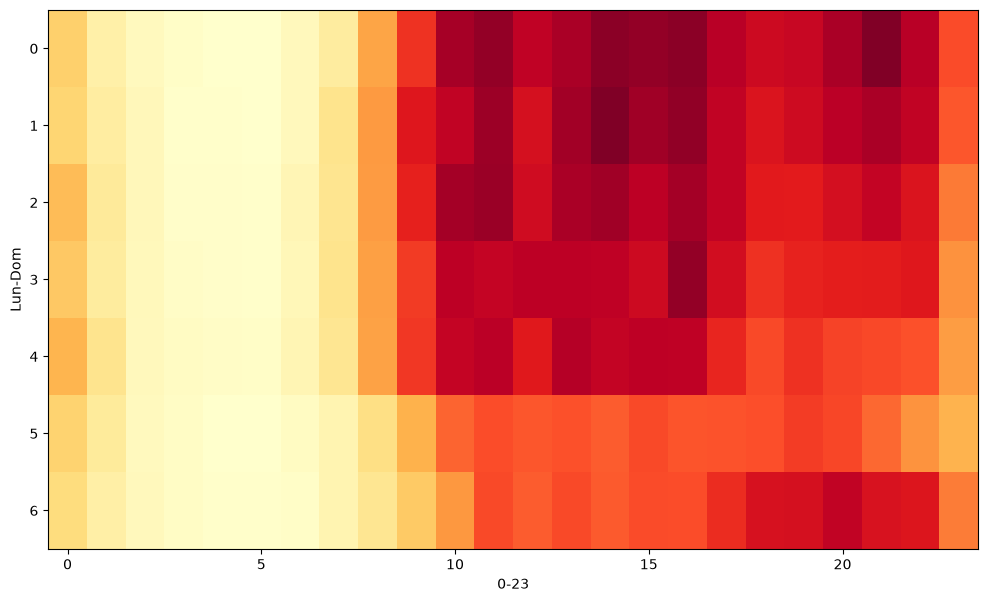

In [24]:
df_11 = orders
df_11["dia"] = orders["order_purchase_timestamp"].dt.dayofweek
df_11["hora"] = orders["order_purchase_timestamp"].dt.hour
lienzo, pintura = plt.subplots(figsize = (12,7))
pivot = df_11.pivot_table(
    index = "dia",
    columns = "hora",
    values = "order_id",
    aggfunc= "count"
)
panel11 = plt.imshow(pivot,
    aspect = "auto",
    cmap = "YlOrRd",
)
pintura.set_ylabel("Lun-Dom")
pintura.set_xlabel("0-23")

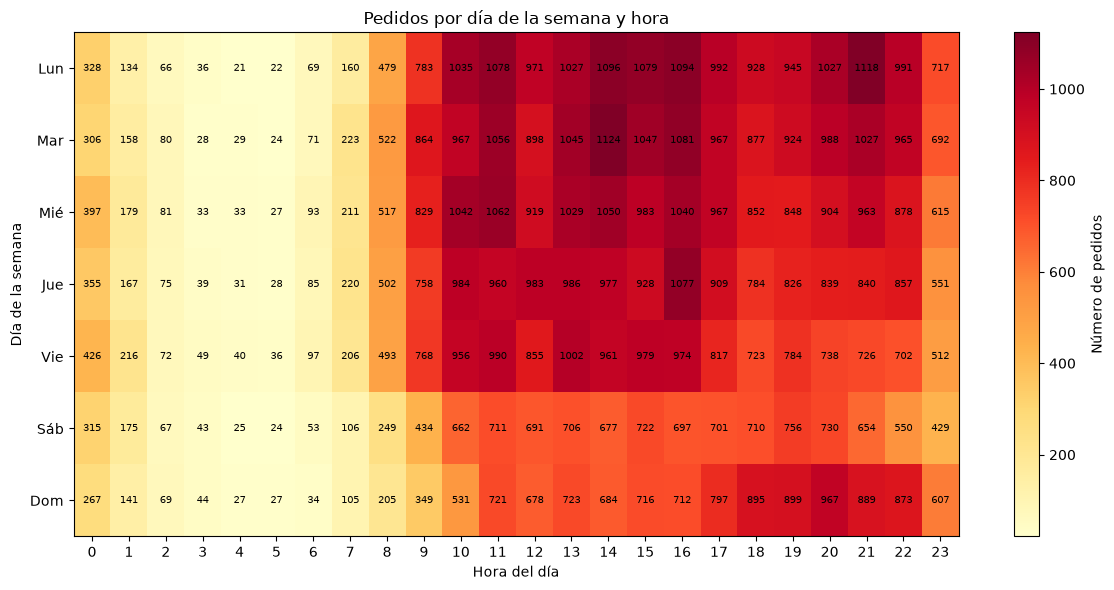

In [25]:
df_11=orders
df_11["dia"] = df_11["order_purchase_timestamp"].dt.dayofweek
df_11["hora"] = df_11["order_purchase_timestamp"].dt.hour
fig, ax = plt.subplots(figsize = (12,6))

pivot = df_11.pivot_table(
    index = "dia",
    columns = "hora",
    values = "order_id",
    aggfunc= "count"
)
panel_df_11 = plt.imshow(pivot,
    aspect = "auto",
    cmap = "YlOrRd",
)
pintura.set_ylabel("Lun-Dom")
pintura.set_xlabel("0-23")
ax.set_yticks(range(7))
ax.set_yticklabels([
    "Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"
])
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_title("Pedidos por día de la semana y hora")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Día de la semana")
fig.colorbar(panel_df_11, ax=ax, label="Número de pedidos")
plt.tight_layout()
for i in range(7):
    for j in range(24):
        ax.text(j, i, pivot.iloc[i, j],
                ha="center", va="center", fontsize=7)
plt.show()

## Dashboard final: subplots + doble eje
``plt.subplots + twinx``
* Reutilizar los dataframes de las gráficas 1, 2, 5 y 11.
* ``fig, axes = plt.subplots(2, 2, figsize=(14,10))``.
* Panel 1: pedidos por mes y, con ``twinx()``, ingreso mensual en el segundo eje (merge ``orders`` + ``order_items``, groupby mes, suma de ``price``).
* Demás paneles: top categorías, boxplot de reseñas y heatmap.
* `` fig.suptitle``, ``plt.tight_layout()`` y ``savefig('dashboard.png', dpi=150)``.

In [26]:
df1 = orders[orders["order_status"] == "delivered"]
df1 = df1[["order_purchase_timestamp", "order_id"]]
df1["month"] = df1["order_purchase_timestamp"].dt.to_period("M")
numero_pedidos=df1.groupby("month")["order_id"].nunique()
####
df_12=orders.merge(order_items, on = "order_id", how = "left")
df_12=df_12[df_12["order_status"] == "delivered"]
df_12["mes"]=df_12["order_purchase_timestamp"].dt.to_period("M")
df_12_ingmen=df_12.groupby("mes")["price"].sum()
###
# Combinar las dos series
resumen=pd.concat(
    [
        numero_pedidos.rename("pedidos"),
        df_12_ingmen.rename("ingresos")
    ],
    axis=1
).loc["2017-01":"2018-08"].dropna()

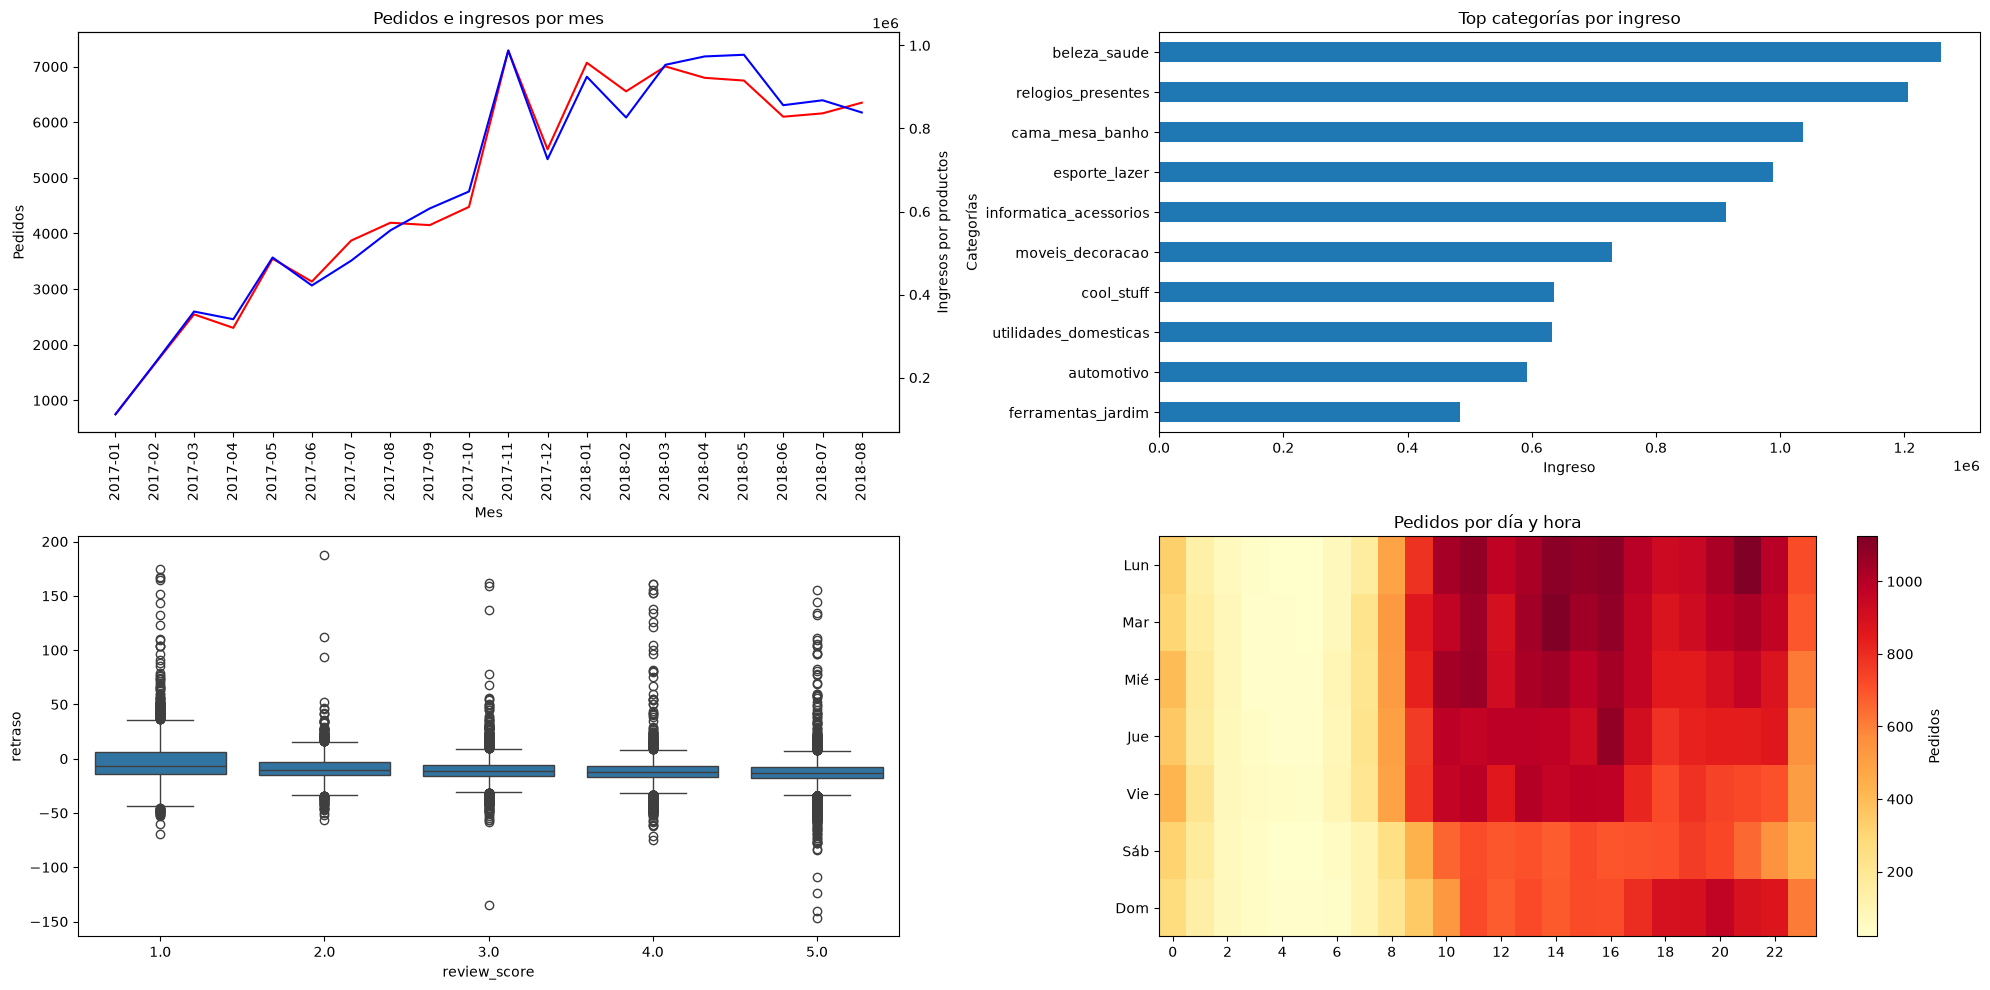

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20,10))
ax1 = axes[0, 0]
ax1.plot(
    resumen.index.astype(str),
    resumen["pedidos"],
    color = "red"
)
ax1.set_title("Pedidos e ingresos por mes")
ax1.set_xlabel("Mes")
ax1.set_ylabel("Pedidos")
ax1.tick_params(axis="x", rotation=90)
ax1b = ax1.twinx()
ax1b.plot(
    resumen.index.astype(str),
    resumen['ingresos'],
    color = "blue"
)
ax1b.set_ylabel('Ingresos por productos')
pane_df_l2 = resultado.plot(
    kind = "barh",
    title = "Top categorías por ingreso",
    xlabel = "Ingreso",
    ylabel = "Categorías",
    ax = axes[0,1]
)
#
ax3 = axes[1,0]
ax3.clear()
sns.boxplot(
    data=merge5,
    x="review_score",
    y="retraso",
    ax=ax3
    )

#
ax4 = axes[1,1]
panel_df_11 = axes[1,1].imshow(pivot,
    aspect = "auto",
    cmap = "YlOrRd",
)
ax4.set_title("Pedidos por día y hora")
ax4.set_yticks(range(7))
ax4.set_yticklabels([
    "Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"
])
ax4.set_xticks(range(0, 24, 2))
ax4.set_xticklabels(range(0, 24, 2))
fig.colorbar(panel_df_11, ax=ax4, label='Pedidos')
plt.tight_layout()
plt.show()
import warnings
warnings.filterwarnings("ignore")